# Raw Time-Series Data Exploration\n\nLoads **raw, unprocessed** rows straight from `sensor_data.db` (`measurement` table) and plots them as-is — no resampling, smoothing, or aggregation.\n\nThe table holds ~14M rows across all directed sender→receiver links, so by default we load one link at a time. Change `SENDER_ID` / `RECEIVER_ID` below to look at a different link."

In [12]:
import sqlite3
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

DB_PATH = Path("sensor_data.db")

SENDER_ID = 7
RECEIVER_ID = 8

In [13]:
## Load raw rows for one directed link (sender -> receiver)

with sqlite3.connect(DB_PATH) as con:
    df_link = pd.read_sql_query(
        """
        SELECT pc_ts, rssi, snr, ok_match, trigger_ms, rx_wait_ms, e2e_ms
        FROM measurement
        WHERE sender_id = ? AND receiver_id = ?
        ORDER BY pc_ts
        """,
        con,
        params=(SENDER_ID, RECEIVER_ID),
    )

df_link["pc_ts"] = pd.to_datetime(df_link["pc_ts"])
print(f"Loaded {len(df_link):,} raw rows for link {SENDER_ID} -> {RECEIVER_ID}")
df_link.head()

DatabaseError: Execution failed on sql '
        SELECT pc_ts, rssi, snr, ok_match, trigger_ms, rx_wait_ms, e2e_ms
        FROM measurement
        WHERE sender_id = ? AND receiver_id = ?
        ORDER BY pc_ts
        ': no such table: measurement

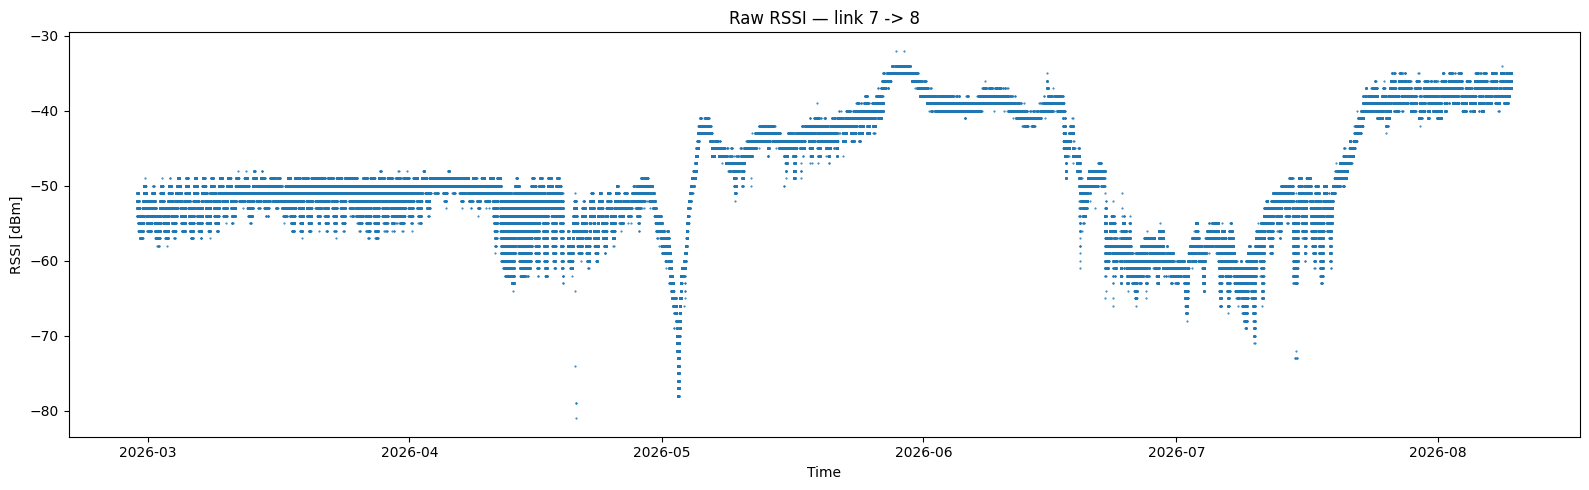

In [ ]:
## Plot raw RSSI over time — every point, no aggregation

fig, ax = plt.subplots(figsize=(16, 5))
ax.plot(df_link["pc_ts"], df_link["rssi"], linewidth=0.5, marker=".", markersize=1, linestyle="none")
ax.set_title(f"Raw RSSI — link {SENDER_ID} -> {RECEIVER_ID}")
ax.set_xlabel("Time")
ax.set_ylabel("RSSI [dBm]")
fig.tight_layout()
plt.show()

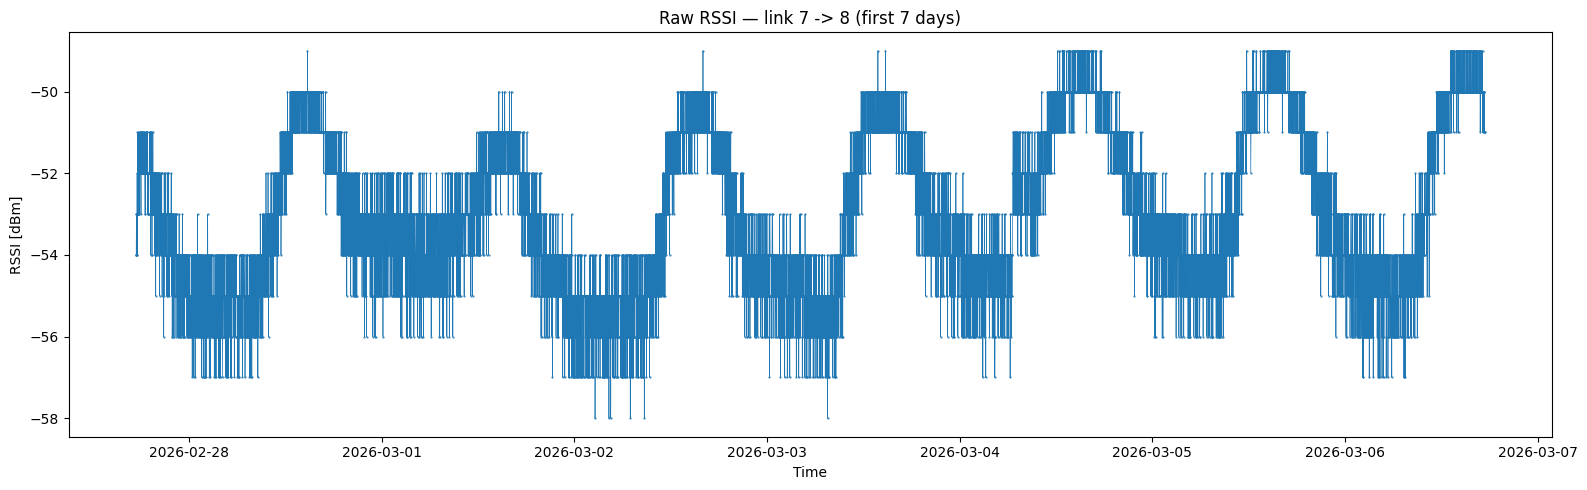

In [ ]:
window_start = df_link["pc_ts"].min()
window_end = window_start + pd.Timedelta(days=7)
df_window = df_link[(df_link["pc_ts"] >= window_start) & (df_link["pc_ts"] < window_end)]

fig, ax = plt.subplots(figsize=(16, 5))
ax.plot(df_window["pc_ts"], df_window["rssi"], linewidth=0.5, marker=".", markersize=1)
ax.set_title(f"Raw RSSI — link {SENDER_ID} -> {RECEIVER_ID} (first 7 days)")
ax.set_xlabel("Time")
ax.set_ylabel("RSSI [dBm]")
fig.tight_layout()
plt.show()


## Plot RSSI over multiple time windows (last 2h / 24h / 3d / 7d / 30d)

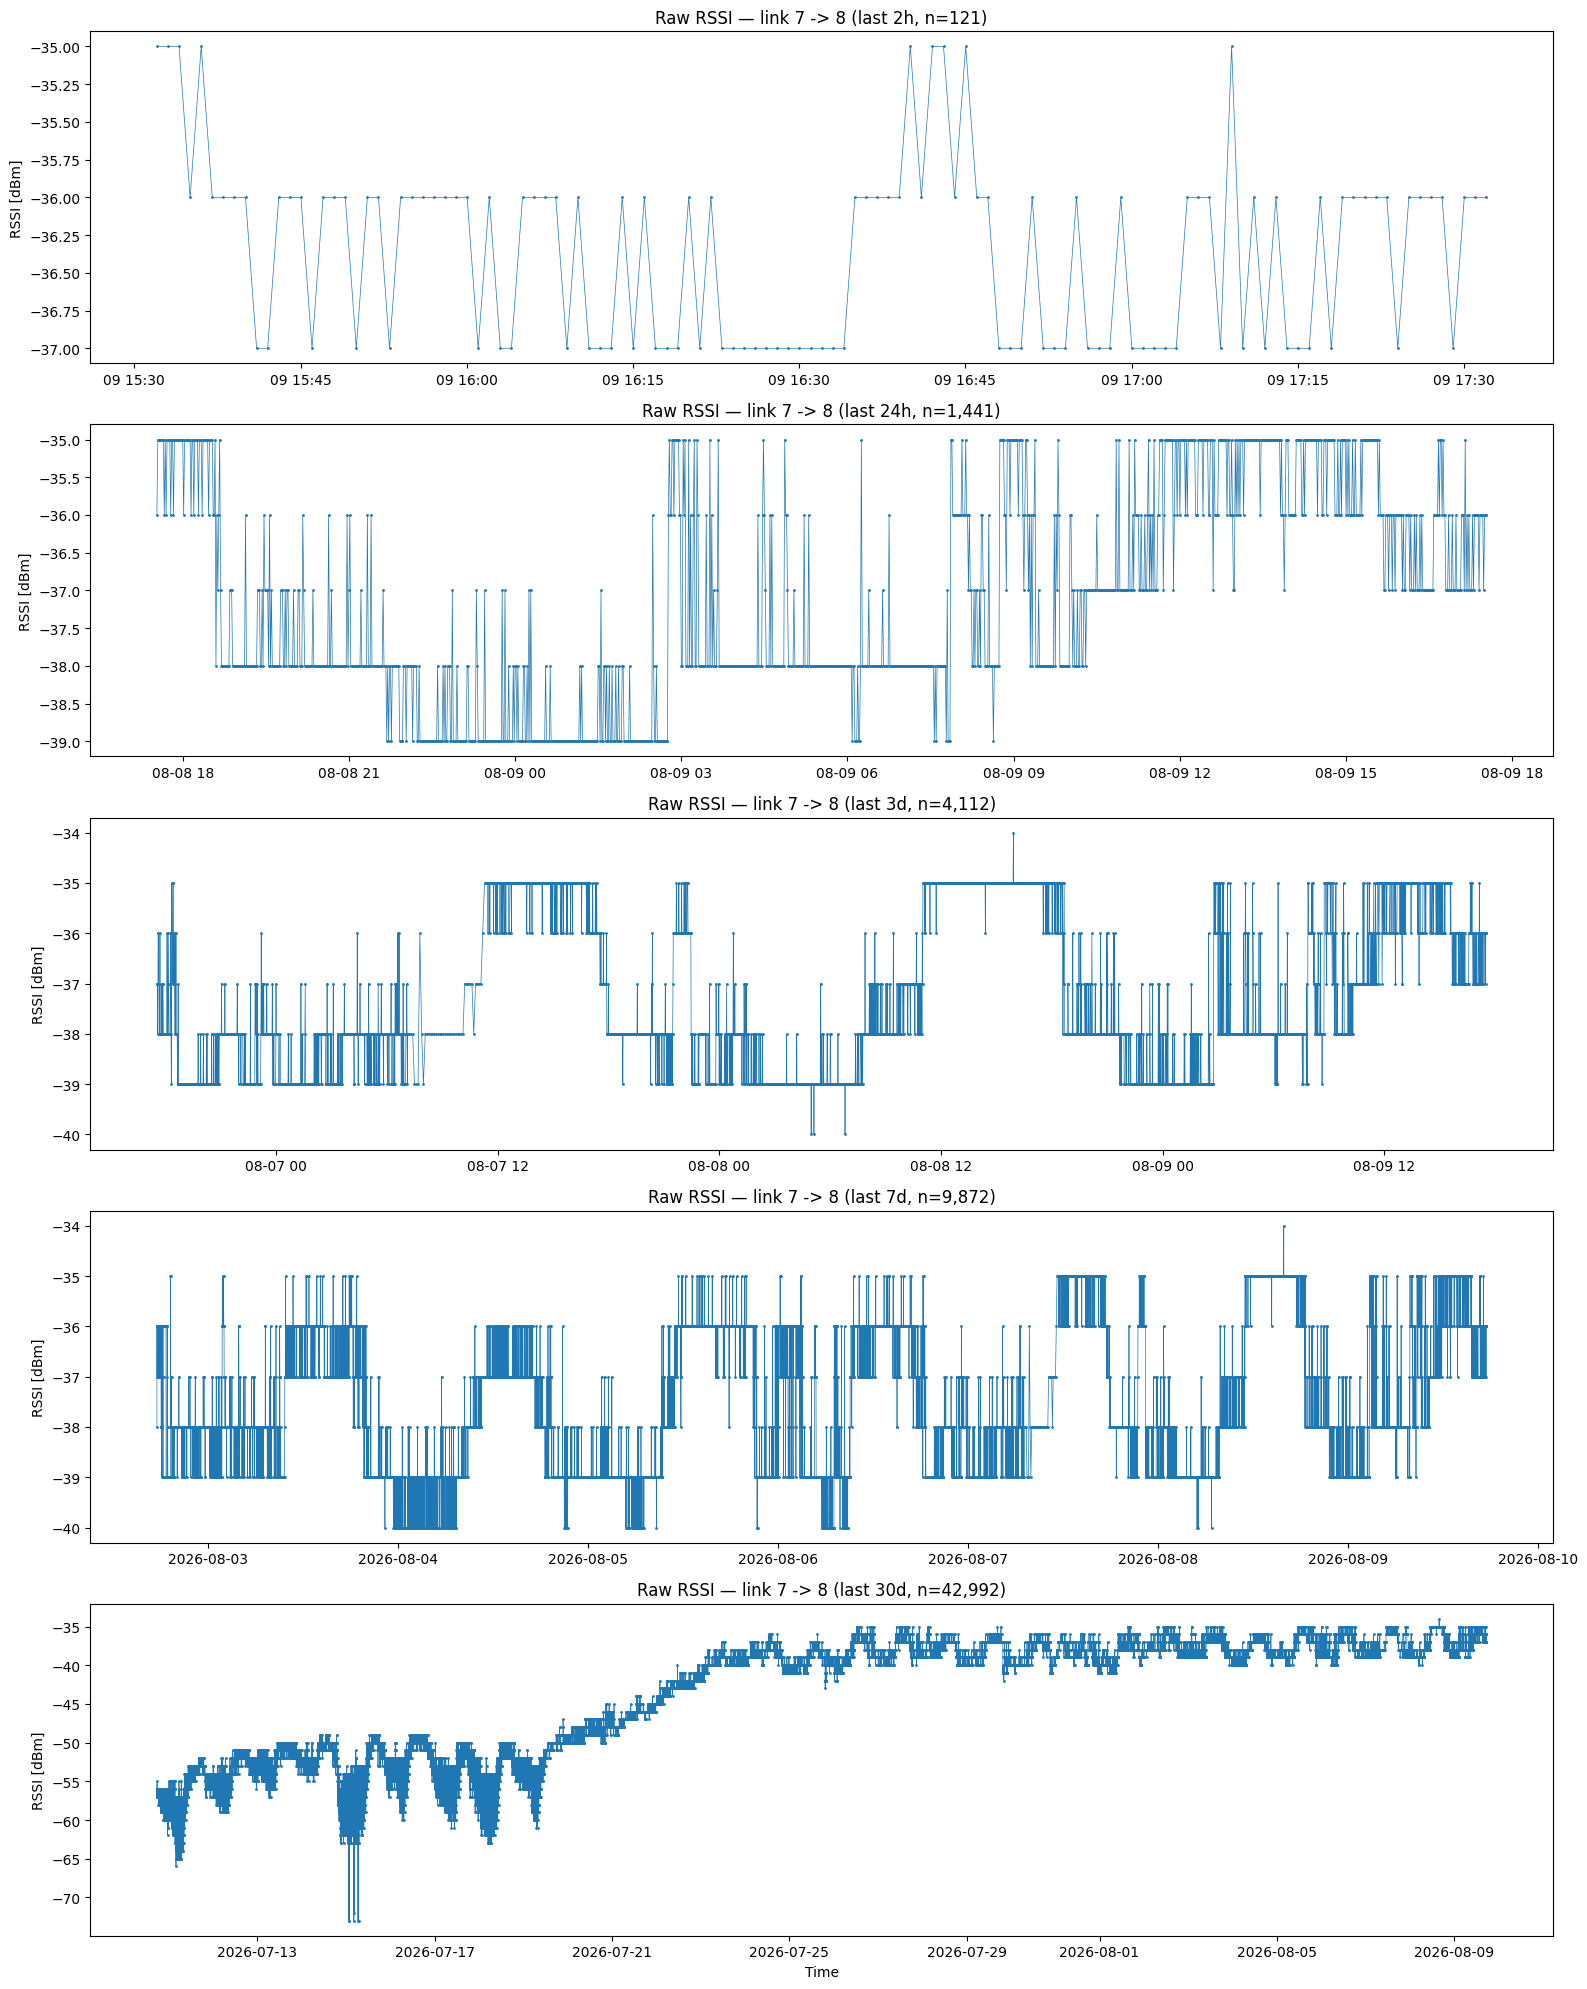

In [ ]:
windows = {
    "2h": pd.Timedelta(hours=2),
    "24h": pd.Timedelta(hours=24),
    "3d": pd.Timedelta(days=3),
    "7d": pd.Timedelta(days=7),
    "30d": pd.Timedelta(days=30),
}

window_end = df_link["pc_ts"].max()

fig, axes = plt.subplots(len(windows), 1, figsize=(16, 4 * len(windows)))

for ax, (label, delta) in zip(axes, windows.items()):
    window_start = window_end - delta
    df_window = df_link[(df_link["pc_ts"] >= window_start) & (df_link["pc_ts"] <= window_end)]
    ax.plot(df_window["pc_ts"], df_window["rssi"], linewidth=0.5, marker="o", markersize=1)
    ax.set_title(f"Raw RSSI — link {SENDER_ID} -> {RECEIVER_ID} (last {label}, n={len(df_window):,})")
    ax.set_ylabel("RSSI [dBm]")

axes[-1].set_xlabel("Time")
fig.tight_layout()
plt.show()


Loaded 249,343 raw rows for link 8 -> 7


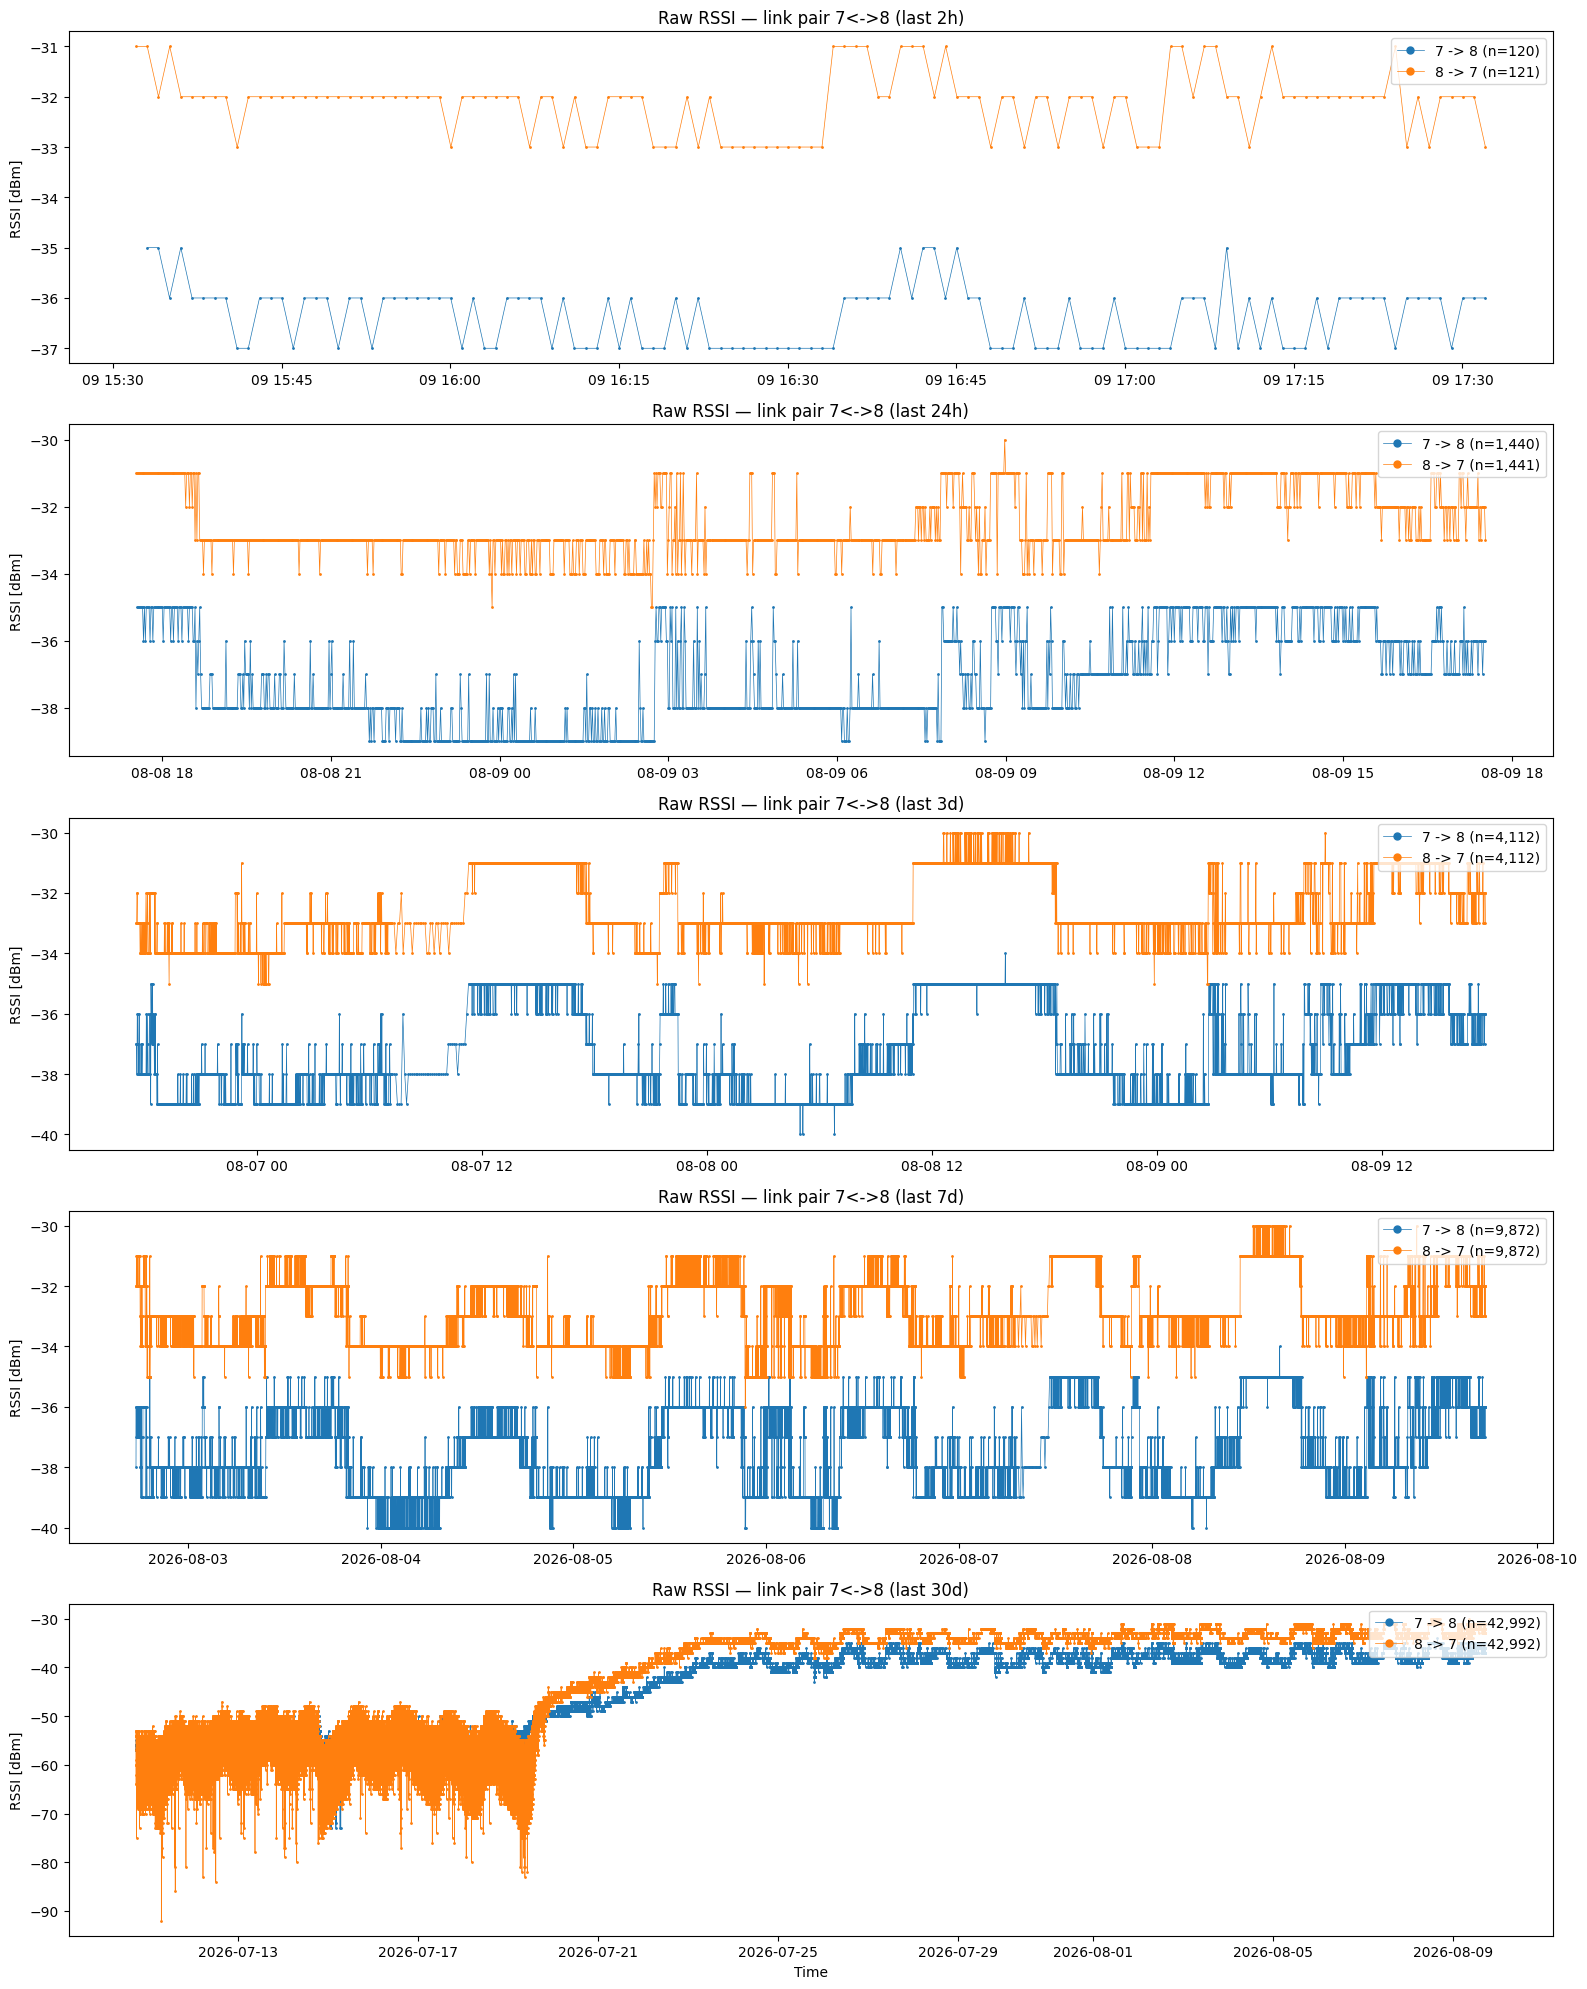

In [ ]:
## Same windows, but overlay both directions of the link pair (A->B and B->A)

with sqlite3.connect(DB_PATH) as con:
    df_link_rev = pd.read_sql_query(
        """
        SELECT pc_ts, rssi, snr, ok_match, trigger_ms, rx_wait_ms, e2e_ms
        FROM measurement
        WHERE sender_id = ? AND receiver_id = ?
        ORDER BY pc_ts
        """,
        con,
        params=(RECEIVER_ID, SENDER_ID),
    )
df_link_rev["pc_ts"] = pd.to_datetime(df_link_rev["pc_ts"])
print(f"Loaded {len(df_link_rev):,} raw rows for link {RECEIVER_ID} -> {SENDER_ID}")

window_end = max(df_link["pc_ts"].max(), df_link_rev["pc_ts"].max())

fig, axes = plt.subplots(len(windows), 1, figsize=(16, 4 * len(windows)))

for ax, (label, delta) in zip(axes, windows.items()):
    window_start = window_end - delta

    df_fwd_window = df_link[(df_link["pc_ts"] >= window_start) & (df_link["pc_ts"] <= window_end)]
    df_rev_window = df_link_rev[(df_link_rev["pc_ts"] >= window_start) & (df_link_rev["pc_ts"] <= window_end)]

    ax.plot(df_fwd_window["pc_ts"], df_fwd_window["rssi"], linewidth=0.5, marker="o", markersize=1,
            label=f"{SENDER_ID} -> {RECEIVER_ID} (n={len(df_fwd_window):,})")
    ax.plot(df_rev_window["pc_ts"], df_rev_window["rssi"], linewidth=0.5, marker="o", markersize=1,
            label=f"{RECEIVER_ID} -> {SENDER_ID} (n={len(df_rev_window):,})")

    ax.set_title(f"Raw RSSI — link pair {SENDER_ID}<->{RECEIVER_ID} (last {label})")
    ax.set_ylabel("RSSI [dBm]")
    ax.legend(loc="upper right", markerscale=5)

axes[-1].set_xlabel("Time")
fig.tight_layout()
plt.show()


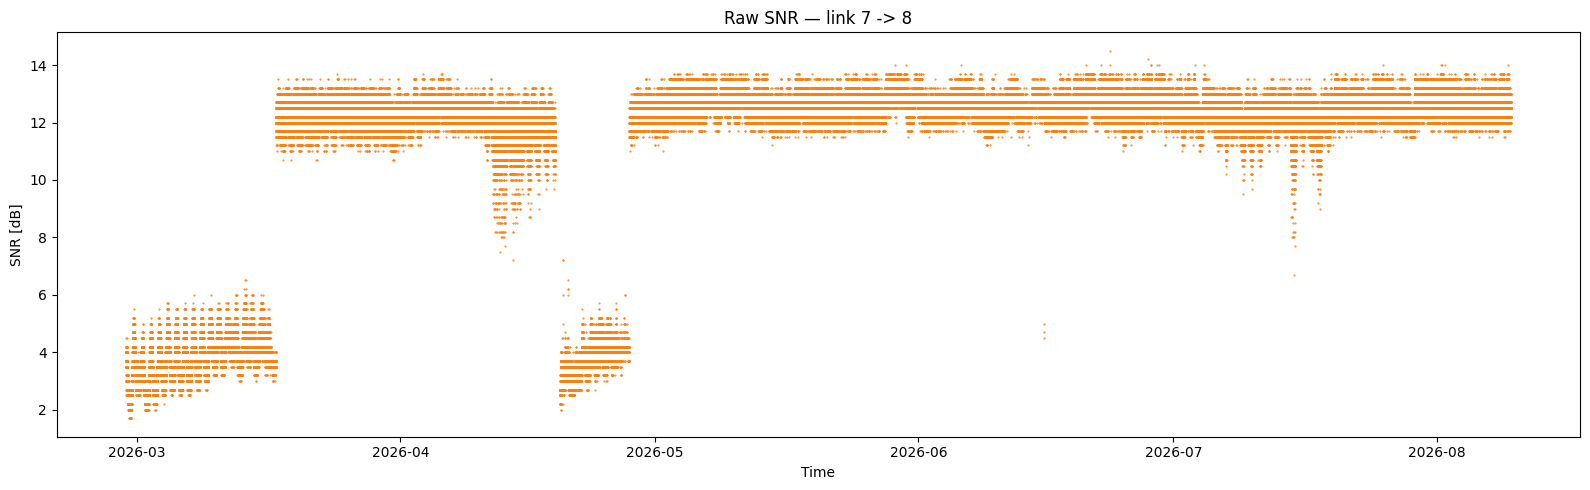

In [ ]:
## Plot raw SNR over time — every point, no aggregation

fig, ax = plt.subplots(figsize=(16, 5))
ax.plot(df_link["pc_ts"], df_link["snr"], linewidth=0.5, marker=".", markersize=1, linestyle="none", color="tab:orange")
ax.set_title(f"Raw SNR — link {SENDER_ID} -> {RECEIVER_ID}")
ax.set_xlabel("Time")
ax.set_ylabel("SNR [dB]")
fig.tight_layout()
plt.show()

## Raw BME environmental data (temperature / humidity / pressure)

BME readings are attached to rows where `sender_id = BME_NODE_ID` (rows also carry `bme_temp`, `bme_hum`, `bme_press`). Same node can appear as sender for multiple receivers, so we deduplicate by timestamp to avoid plotting the same raw reading multiple times.

In [ ]:
BME_NODE_ID = 5

with sqlite3.connect(DB_PATH) as con:
    df_bme = pd.read_sql_query(
        """
        SELECT pc_ts, bme_temp, bme_hum, bme_press
        FROM measurement
        WHERE sender_id = ? AND bme_temp IS NOT NULL
        ORDER BY pc_ts
        """,
        con,
        params=(BME_NODE_ID,),
    )

df_bme["pc_ts"] = pd.to_datetime(df_bme["pc_ts"])
df_bme = df_bme.drop_duplicates(subset="pc_ts")
print(f"Loaded {len(df_bme):,} raw BME rows for node {BME_NODE_ID}")
df_bme.head()

Loaded 352,811 raw BME rows for node 5


,pc_ts,bme_temp,bme_hum,bme_press
0,2026-02-27 17:23:57,0.00,0.0,0.0
3,2026-02-27 17:23:58,0.00,0.0,0.0
5,2026-02-27 17:24:18,12.36,100.0,977.6
7,2026-02-27 17:25:21,0.00,0.0,0.0
10,2026-02-27 17:25:22,0.00,0.0,0.0


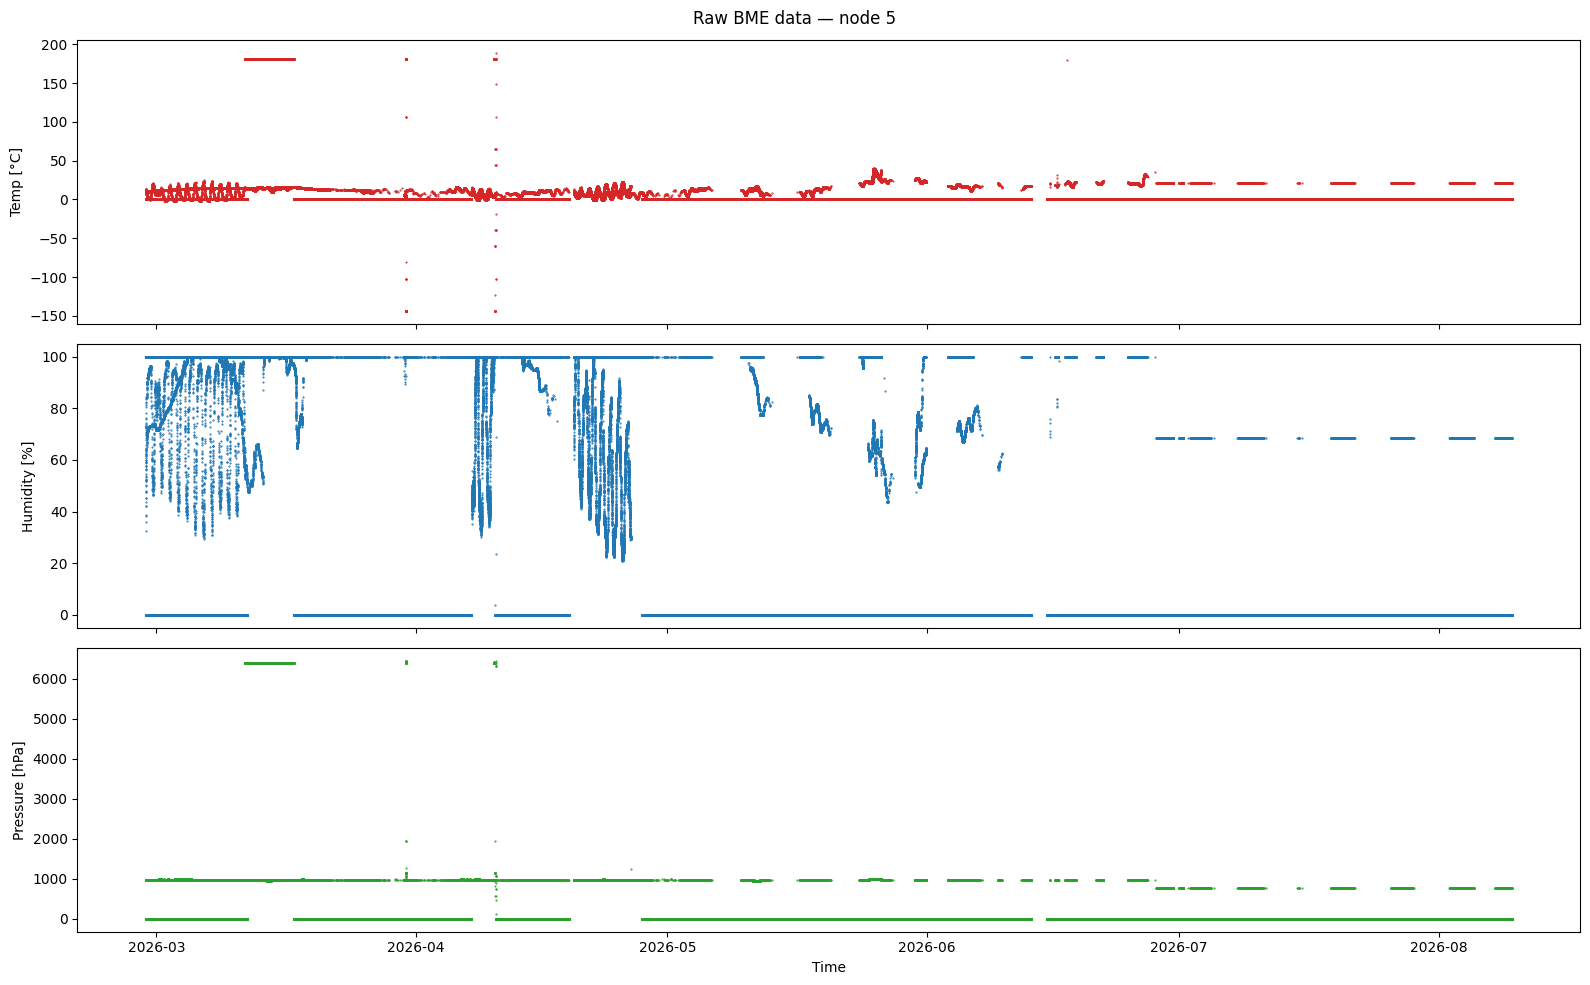

In [ ]:
fig, axes = plt.subplots(3, 1, figsize=(16, 10), sharex=True)

axes[0].plot(df_bme["pc_ts"], df_bme["bme_temp"], linewidth=0.5, marker=".", markersize=1, linestyle="none", color="tab:red")
axes[0].set_ylabel("Temp [°C]")

axes[1].plot(df_bme["pc_ts"], df_bme["bme_hum"], linewidth=0.5, marker=".", markersize=1, linestyle="none", color="tab:blue")
axes[1].set_ylabel("Humidity [%]")

axes[2].plot(df_bme["pc_ts"], df_bme["bme_press"], linewidth=0.5, marker=".", markersize=1, linestyle="none", color="tab:green")
axes[2].set_ylabel("Pressure [hPa]")
axes[2].set_xlabel("Time")

fig.suptitle(f"Raw BME data — node {BME_NODE_ID}")
fig.tight_layout()
plt.show()